# House Price Estimation (Ames, Iowa)
Estimate the sale price of a house from its characteristics. This is the classic Kaggle *House Prices* dataset: 1,460 homes sold in Ames, Iowa between 2006 and 2010, with 79 descriptive features.

**Target:** `SalePrice` — modelled as `log1p(SalePrice)`, so errors are relative (Kaggle scores on RMSE of log price).  
**Metrics:** CV RMSE on log scale for model selection; RMSE, MAE (dollars) and R² on a held-out test set.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style='whitegrid'); SEED = 42

## 1. Load the data
Kaggle requires a login, so the same table is loaded from OpenML (dataset 42165, `house_prices`), which is an exact copy of Kaggle's `train.csv`.

In [2]:
df = fetch_openml(data_id=42165, as_frame=True, data_home='data').frame
print(df.shape)
df[['Id', 'OverallQual', 'GrLivArea', 'Neighborhood', 'YearBuilt', 'GarageCars', 'SalePrice']].head()

(1460, 81)


,Id,OverallQual,GrLivArea,Neighborhood,YearBuilt,GarageCars,SalePrice
0,1,7,1710,CollgCr,2003,2,208500
1,2,6,1262,Veenker,1976,2,181500
2,3,7,1786,CollgCr,2001,2,223500
3,4,7,1717,Crawfor,1915,3,140000
4,5,8,2198,NoRidge,2000,3,250000


## 2. The target: sale price

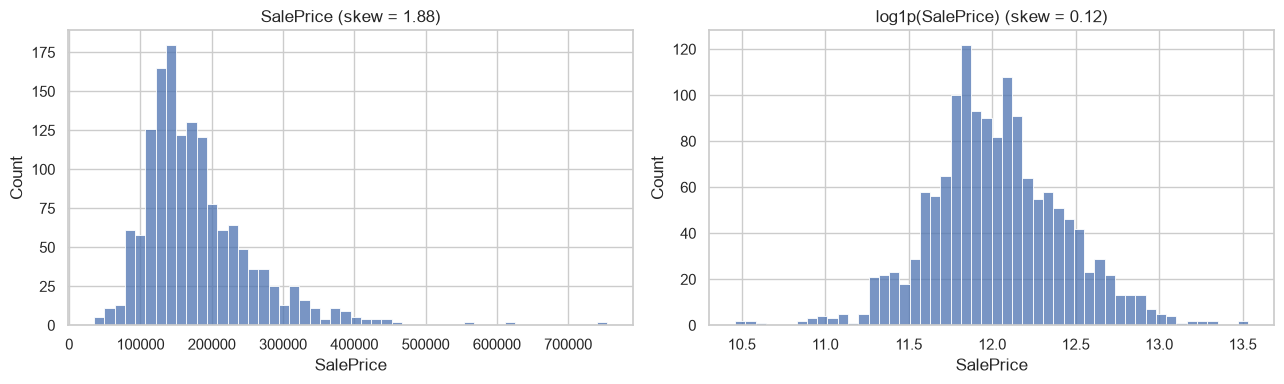

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df['SalePrice'], bins=50, ax=axes[0]).set_title(f"SalePrice (skew = {df['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(df['SalePrice']), bins=50, ax=axes[1]).set_title(f"log1p(SalePrice) (skew = {np.log1p(df['SalePrice']).skew():.2f})")
plt.tight_layout()

Prices are right-skewed (a long tail of expensive homes). On the log scale the distribution is close to normal, which suits linear models and makes the error *relative* instead of absolute.

## 3. Missing values

In [4]:
miss = df.isna().mean().mul(100).sort_values(ascending=False)
miss[miss > 0].round(1).to_frame('% missing')

,% missing
PoolQC,99.5
MiscFeature,96.3
Alley,93.8
Fence,80.8
FireplaceQu,47.3
LotFrontage,17.7
GarageFinish,5.5
GarageQual,5.5
GarageYrBlt,5.5
GarageType,5.5


Most 'missing' values are not errors: `PoolQC`, `Alley`, `Fence`, `FireplaceQu` are empty because the house simply has no pool / alley / fence / fireplace. `LotFrontage` is genuinely unknown for ~18% of houses.

## 4. What correlates with price

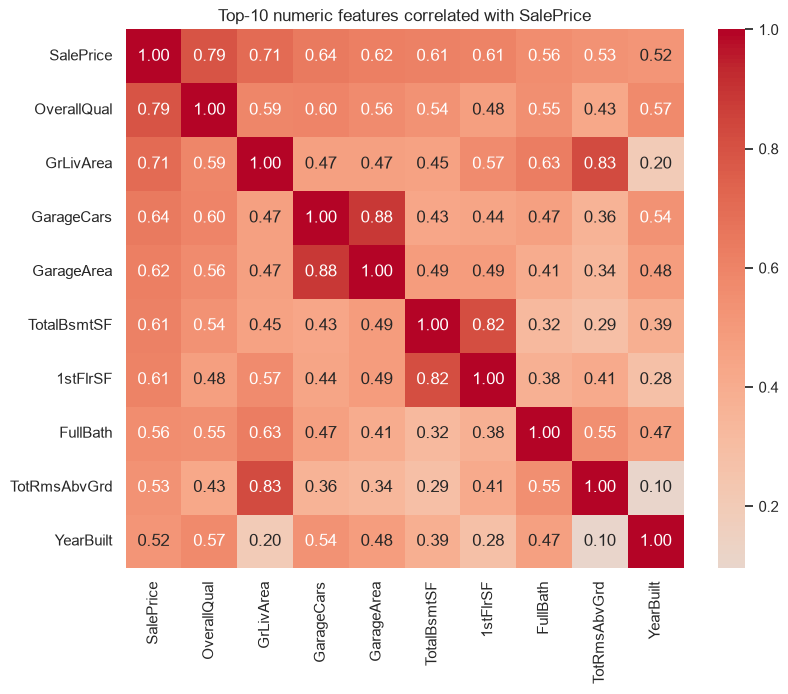

In [5]:
num = df.select_dtypes('number').drop(columns='Id')
top = num.corr()['SalePrice'].abs().sort_values(ascending=False).head(10).index
plt.figure(figsize=(9, 7))
sns.heatmap(num[top].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Top-10 numeric features correlated with SalePrice');

`OverallQual` (0.79) and `GrLivArea` (0.71) dominate. Some top features are near-duplicates (`GarageCars`/`GarageArea` 0.88, `TotalBsmtSF`/`1stFlrSF` 0.82), so only one of each pair is needed.

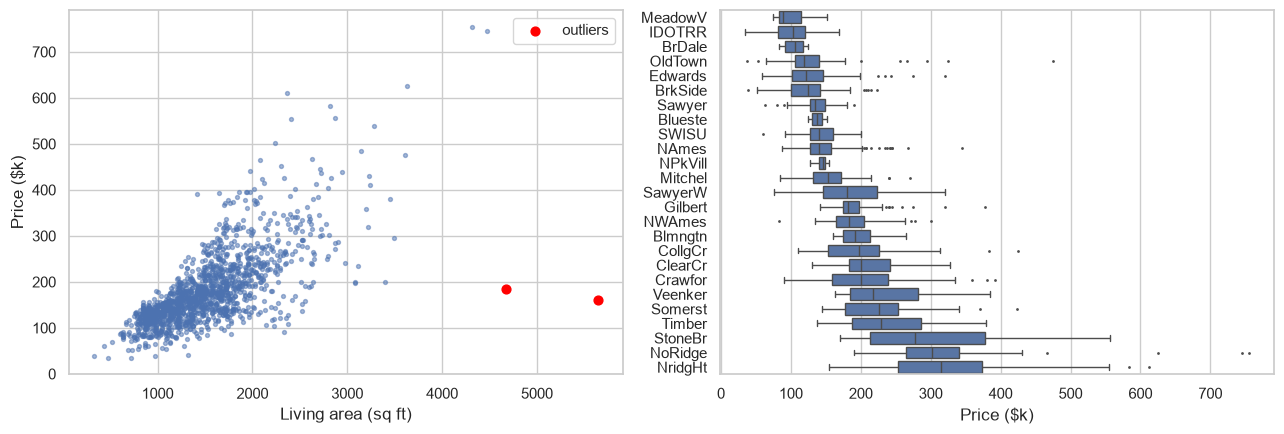

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
out = (df['GrLivArea'] > 4000) & (df['SalePrice'] < 300_000)
axes[0].scatter(df['GrLivArea'], df['SalePrice'] / 1000, s=8, alpha=0.5)
axes[0].scatter(df.loc[out, 'GrLivArea'], df.loc[out, 'SalePrice'] / 1000, s=40, color='red', label='outliers')
axes[0].set(xlabel='Living area (sq ft)', ylabel='Price ($k)'); axes[0].legend()
order = df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(data=df, y='Neighborhood', x=df['SalePrice'] / 1000, order=order, ax=axes[1], fliersize=1)
axes[1].set(xlabel='Price ($k)', ylabel='')
plt.tight_layout()

Two very large houses (red) sold for far less than their size suggests — the dataset author documents them as partial sales and recommends removing houses over 4,000 sq ft. I drop these 2 rows. Neighborhood clearly shifts the price level: medians range from ~$88k to ~$315k.

In [7]:
df = df[~out].copy()
y = np.log1p(df['SalePrice'])
print(df.shape)

(1458, 81)


## 5. Baseline from a single feature
A simple linear regression on living area alone, to have a reference point:

In [8]:
cv = KFold(5, shuffle=True, random_state=SEED)
def cv_scores(model, X, y):
    r = cross_validate(model, X, y, cv=cv, n_jobs=-1, scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'})
    return {'CV RMSE (log)': -r['test_rmse'].mean(), 'CV R²': r['test_r2'].mean()}

idx_train, idx_test = train_test_split(df.index, test_size=0.2, random_state=SEED)
pd.Series(cv_scores(LinearRegression(), df.loc[idx_train, ['GrLivArea']], y[idx_train])).round(4)

CV RMSE (log)    0.2706
CV R²            0.5283
dtype: float64

## 6. All 79 features vs. a short, understandable set
For the web demo a user has to fill in a form, so I want ~12 features that anyone can answer. First, how much accuracy does that cost compared to using everything?

In [9]:
all_X = df.drop(columns=['Id', 'SalePrice'])
prep_all = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), make_column_selector(dtype_include='number')),
    ('cat', make_pipeline(SimpleImputer(strategy='constant', fill_value='None'), OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
     make_column_selector(dtype_exclude='number')),
])
num_cols = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'YearRemodAdd', 'FullBath', 'Fireplaces', 'LotArea']
cat_cols = ['Neighborhood', 'ExterQual', 'KitchenQual', 'CentralAir']
features = num_cols + cat_cols
prep = ColumnTransformer([('num', StandardScaler(), num_cols),
                          ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)])

rows = []
for name, est in [('Ridge', Ridge(alpha=10)), ('HistGradientBoosting', HistGradientBoostingRegressor(random_state=SEED))]:
    rows.append({'features': 'all 79', 'model': name, **cv_scores(Pipeline([('prep', prep_all), ('model', est)]), all_X.loc[idx_train], y[idx_train])})
    rows.append({'features': f'{len(features)} selected', 'model': name, **cv_scores(Pipeline([('prep', prep), ('model', est)]), df.loc[idx_train, features], y[idx_train])})
pd.DataFrame(rows).round(4)

,features,model,CV RMSE (log),CV R²
0,all 79,Ridge,0.1127,0.9181
1,13 selected,Ridge,0.1327,0.8870
2,all 79,HistGradientBoosting,0.1288,0.8937
3,13 selected,HistGradientBoosting,0.1435,0.8680


Using all 79 features lowers the CV RMSE by about 0.02 on the log scale (roughly 2 percentage points of relative error). The 13 selected features keep most of the signal, so the demo model uses them:

| Feature | Meaning |
|---|---|
| OverallQual | overall material & finish, 1–10 |
| GrLivArea | above-ground living area, sq ft |
| TotalBsmtSF | basement area, sq ft |
| GarageCars | garage capacity in cars |
| YearBuilt / YearRemodAdd | construction / remodel year |
| FullBath, Fireplaces | counts |
| LotArea | lot size, sq ft |
| Neighborhood | one of 25 Ames neighborhoods |
| ExterQual / KitchenQual | exterior / kitchen quality (Poor … Excellent) |
| CentralAir | yes / no |

## 7. Model comparison (13 features, 5-fold CV)

In [10]:
X_train, X_test = df.loc[idx_train, features], df.loc[idx_test, features]
y_train, y_test = y[idx_train], y[idx_test]
models = {
    'Ridge': Ridge(alpha=3.0),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=600, learning_rate=0.03, max_depth=3, subsample=0.8, random_state=SEED),
    'HistGradientBoosting': HistGradientBoostingRegressor(max_iter=500, learning_rate=0.04, max_leaf_nodes=15,
                                                          min_samples_leaf=10, l2_regularization=1.0, random_state=SEED),
}
res = pd.DataFrame([{'model': n, **cv_scores(Pipeline([('prep', prep), ('model', m)]), X_train, y_train)} for n, m in models.items()])
res.sort_values('CV RMSE (log)').round(4)

,model,CV RMSE (log),CV R²
0,Ridge,0.1318,0.8884
2,Gradient Boosting,0.1346,0.8837
3,HistGradientBoosting,0.1381,0.8778
1,Random Forest,0.1403,0.8741


With a small dataset (≈1,150 training homes) and mostly monotonic relationships on the log scale, regularised **Ridge regression is as good as or better than the tree ensembles** — and it is the simplest and most explainable, so it is the final model.

A quick check of the regularisation strength:

In [11]:
pd.DataFrame([{'alpha': a, **cv_scores(Pipeline([('prep', prep), ('model', Ridge(alpha=a))]), X_train, y_train)}
              for a in [0.1, 1, 3, 10, 30]]).round(4)

,alpha,CV RMSE (log),CV R²
0,0.1,0.1317,0.8884
1,1.0,0.1317,0.8885
2,3.0,0.1318,0.8884
3,10.0,0.1327,0.8870
4,30.0,0.1346,0.8838


## 8. Final evaluation on the test set

In [12]:
final = Pipeline([('prep', prep), ('model', Ridge(alpha=3.0))]).fit(X_train, y_train)
pred = np.expm1(final.predict(X_test)); price = np.expm1(y_test)
print(f'RMSE  ${np.sqrt(mean_squared_error(price, pred)):,.0f}')
print(f'MAE   ${mean_absolute_error(price, pred):,.0f}')
print(f'R²    {r2_score(price, pred):.3f}')
print(f'RMSE (log) {np.sqrt(mean_squared_error(y_test, np.log1p(pred))):.4f}')
print(f'Median relative error {np.median(np.abs(pred - price) / price):.1%}')

RMSE  $23,453
MAE   $17,231
R²    0.900
RMSE (log) 0.1429
Median relative error 7.7%


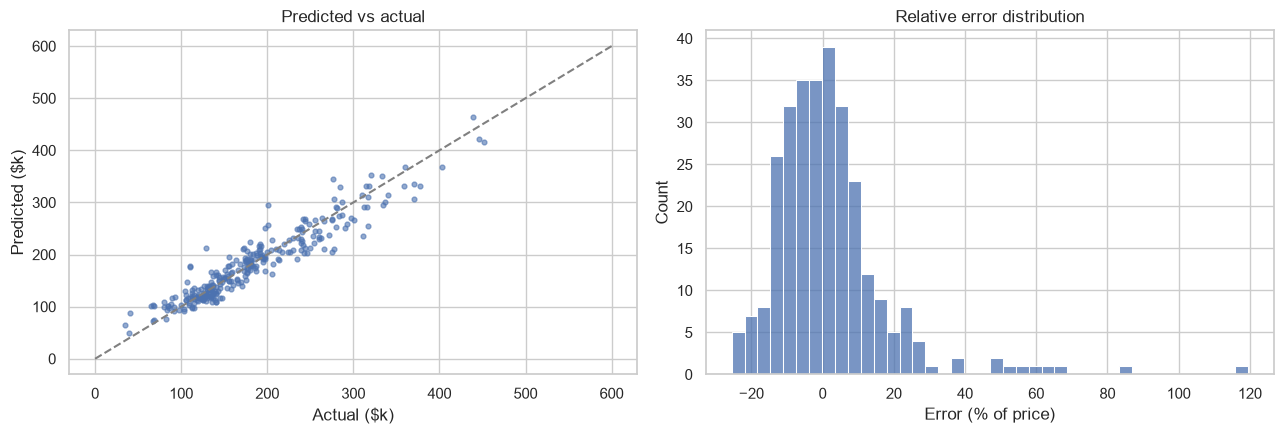

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(price / 1000, pred / 1000, s=12, alpha=0.6)
axes[0].plot([0, 600], [0, 600], '--', color='grey'); axes[0].set(xlabel='Actual ($k)', ylabel='Predicted ($k)', title='Predicted vs actual')
rel = (pred - price) / price
sns.histplot(rel * 100, bins=40, ax=axes[1]); axes[1].set(xlabel='Error (% of price)', title='Relative error distribution')
plt.tight_layout()

### What the model learned
Ridge coefficients on standardised inputs (log-price change per 1 std / per category):

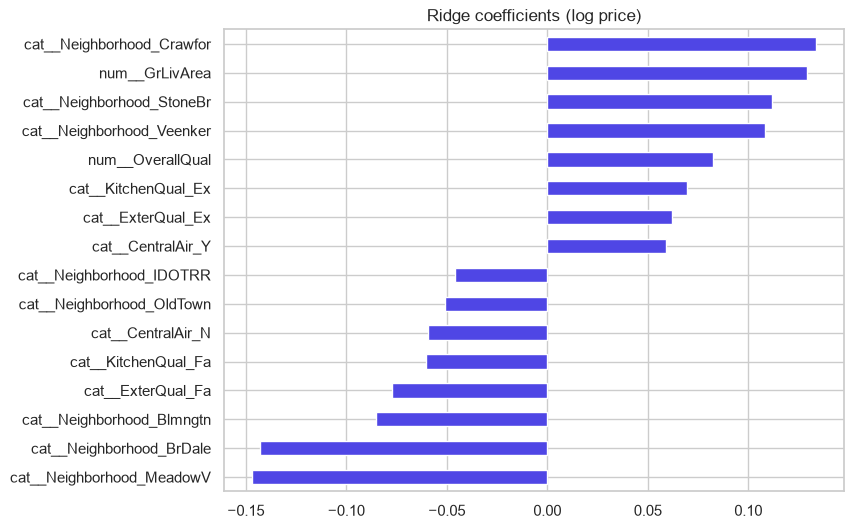

In [14]:
coef = pd.Series(final.named_steps['model'].coef_, index=final.named_steps['prep'].get_feature_names_out())
coef = coef.sort_values()
pd.concat([coef.head(8), coef.tail(8)]).plot.barh(figsize=(8, 6), color='#4f46e5', title='Ridge coefficients (log price)');

Living area and overall quality are the strongest numeric drivers. Location adds a premium (e.g. Crawford, Stone Brook, Veenker) or a discount (Meadow Village, Briardale); fair exterior/kitchen quality and missing central air each lower the estimate by roughly 6–8%.

## 9. Conclusions
- With 13 easy-to-answer features the model estimates prices with a median error of about 8% (R² ≈ 0.90 on unseen houses).
- On this small dataset a well-regularised linear model on log price beats Random Forest and boosting.
- Using all 79 features would improve the error by about 2 percentage points — a fair trade for a 13-field form.

The production version of this pipeline is in `train.py`; it is exported to ONNX and runs in the web demo.